In [27]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("BigD-Course-SparkRDD") \
    .master("spark://spark-master:7077") \
    .getOrCreate()
    
sc = spark.sparkContext

In [28]:
spark

# Задание 1. Исследование структуры данных

In [67]:
import json

In [68]:
rdd = sc.textFile("/opt/spark/data/flights.json").map(json.loads)

In [69]:
rdd.cache()

PythonRDD[57] at RDD at PythonRDD.scala:53

In [70]:
rdd.take(1)

[{'FL_DATE': '2006-01-01',
  'DEP_DELAY': 5,
  'ARR_DELAY': 19,
  'AIR_TIME': 350,
  'DISTANCE': 2475,
  'DEP_TIME': 9.083333,
  'ARR_TIME': 12.483334}]

In [71]:
rdd.first().keys()

dict_keys(['FL_DATE', 'DEP_DELAY', 'ARR_DELAY', 'AIR_TIME', 'DISTANCE', 'DEP_TIME', 'ARR_TIME'])

In [72]:
dep_delays = rdd.map(lambda x: x.get('DEP_DELAY')).filter(lambda x: x is not None)


In [73]:
(dep_delays.min(), dep_delays.max(), dep_delays.mean())

(-1197, 1379, 8.651135000000078)

In [74]:
distance = rdd.map(lambda x: x.get('DISTANCE')).filter(lambda x: x is not None)

In [75]:
(distance.min(), distance.max(), distance.mean())

(30, 4962, 741.2585449999998)

In [76]:
air_time = rdd.map(lambda x: x.get('ARR_DELAY')).filter(lambda x: x is not None)

In [77]:
(air_time.min(), air_time.max(), air_time.mean())

(-197, 1374, 6.400657999999996)

In [79]:
rdd.filter(lambda x: x.get('ARR_DELAY', 0) < 0).count()

534655

In [80]:
rdd.filter(lambda x: x.get('DISTANCE', 0) <= 0).count()


0

In [101]:
rdd.filter(lambda x: x.get("AIR_TIME", 0) <= 0).count()

10

# Задание 2. Анализ временных паттернов

In [110]:
def time_of_day(dep_time):
    if dep_time is None:
        return "unknown"
    if 6 <= dep_time < 12:
        return "morning"
    elif 12 <= dep_time < 18:
        return "day"
    elif 18 <= dep_time < 24:
        return "evening"
    else:
        return "night"

In [111]:
tod_rdd = (
    rdd
    .filter(lambda x: x['DEP_DELAY'] is not None and x['ARR_DELAY'] is not None)
    .map(lambda x: (
        time_of_day(x['DEP_TIME']),
        (x['DEP_DELAY'], x['ARR_DELAY'], 1)
    ))
    .reduceByKey(lambda a, b: (
        a[0] + b[0],
        a[1] + b[1],
        a[2] + b[2]
    ))
    .mapValues(lambda x: (
        x[0] / x[2],   # средняя задержка вылета
        x[1] / x[2]    # средняя задержка прилёта
    ))
)


In [112]:
tod_results = tod_rdd.collect()
tod_results

[('evening', (18.093453860228855, 15.36268217858736)),
 ('night', (8.780055183287347, 7.272171856523453)),
 ('morning', (2.6072886750184927, 0.5800377490608802)),
 ('day', (9.226749095692206, 6.991139756658994))]

In [113]:
import matplotlib.pyplot as plt

In [114]:
labels = [x[0] for x in tod_results]
dep_delays = [x[1][0] for x in tod_results]
arr_delays = [x[1][1] for x in tod_results]

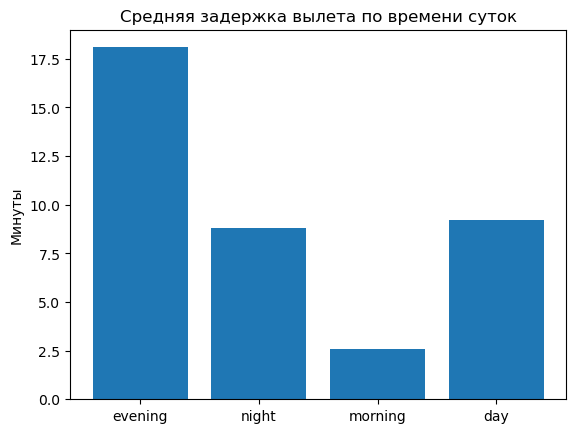

In [115]:
plt.figure()
plt.bar(labels, dep_delays)
plt.title("Средняя задержка вылета по времени суток")
plt.ylabel("Минуты")
plt.show()

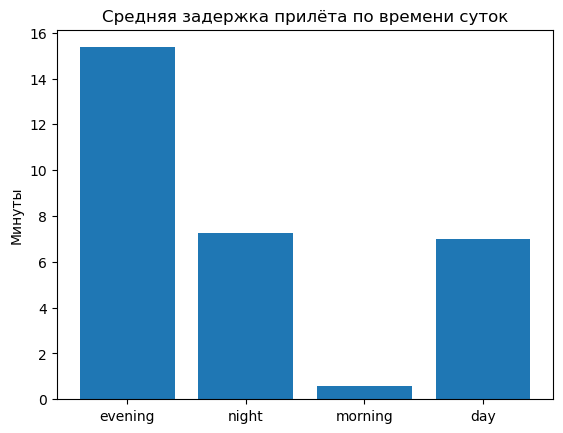

In [116]:
plt.figure()
plt.bar(labels, arr_delays)
plt.title("Средняя задержка прилёта по времени суток")
plt.ylabel("Минуты")
plt.show()

In [117]:
from datetime import datetime

In [118]:
def weekday(date_str):
    return datetime.strptime(date_str, "%Y-%m-%d").weekday() 

In [119]:
weekday_rdd = (
    rdd
    .filter(lambda x: x['DEP_DELAY'] is not None)
    .map(lambda x: (
        weekday(x['FL_DATE']),
        (x['DEP_DELAY'], x['DEP_DELAY']**2, 1)
    ))
    .reduceByKey(lambda a, b: (
        a[0] + b[0],
        a[1] + b[1],
        a[2] + b[2]
    ))
    .mapValues(lambda x: (
        x[0] / x[2],                      # среднее
        (x[1] / x[2]) - (x[0] / x[2])**2  # дисперсия
    ))
)


In [120]:
weekday_results = sorted(weekday_rdd.collect())
weekday_results

[(0, (12.006795664856165, 1298.8773741066077)),
 (1, (6.565760838164205, 784.5677678411896)),
 (2, (6.09666498120342, 648.5400949152721)),
 (3, (6.4434710289463855, 848.6740720127688)),
 (4, (10.837042116126844, 1202.742060508554)),
 (5, (7.726567782466171, 817.8923086089718)),
 (6, (10.345628636069813, 1095.6113504774735))]

In [121]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
variance = [x[1][1] for x in weekday_results]

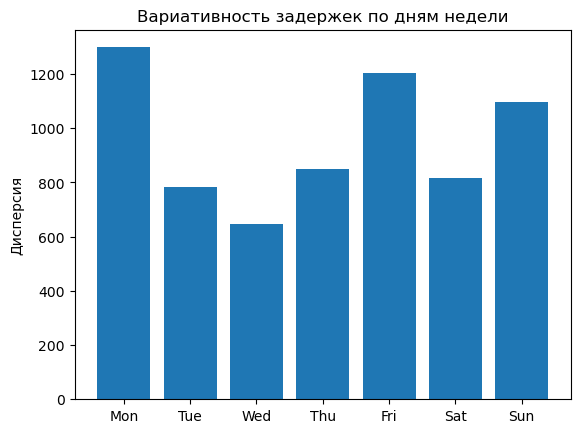

In [122]:
plt.figure()
plt.bar(days, variance)
plt.title("Вариативность задержек по дням недели")
plt.ylabel("Дисперсия")
plt.show()

In [123]:
def month(date_str):
    return int(date_str.split("-")[1])

In [124]:
month_rdd = (
    rdd
    .filter(lambda x: x['DEP_DELAY'] is not None)
    .map(lambda x: (month(x['FL_DATE']), (x['DEP_DELAY'], 1)))
    .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
    .mapValues(lambda x: x[0] / x[1])
)

In [125]:
month_results = sorted(month_rdd.collect())
month_results

[(1, 8.05607493027906), (2, 9.440354060529927)]

# Задание 3. Корреляционный анализ

In [129]:
dep_arr_rdd = rdd.filter(lambda x: x['DEP_DELAY'] is not None and x['ARR_DELAY'] is not None) \
                         .map(lambda x: (x['DEP_DELAY'], x['ARR_DELAY']))

In [130]:
distance_airtime_rdd = rdd.filter(lambda x: x['DISTANCE'] is not None and x['AIR_TIME'] is not None) \
                          .map(lambda x: (x['DISTANCE'], x['AIR_TIME']))

In [131]:
dep_time_delay_rdd = rdd.filter(lambda x: x['DEP_TIME'] is not None and x['DEP_DELAY'] is not None) \
                        .map(lambda x: (x['DEP_TIME'], x['DEP_DELAY']))

In [132]:
def pearson_corr(rdd):
    n = rdd.count()
    sum_x = rdd.map(lambda x: x[0]).sum()
    sum_y = rdd.map(lambda x: x[1]).sum()
    sum_x2 = rdd.map(lambda x: x[0]**2).sum()
    sum_y2 = rdd.map(lambda x: x[1]**2).sum()
    sum_xy = rdd.map(lambda x: x[0]*x[1]).sum()
    
    numerator = sum_xy - (sum_x * sum_y) / n
    denominator = ((sum_x2 - sum_x**2 / n) * (sum_y2 - sum_y**2 / n)) ** 0.5
    return numerator / denominator

In [133]:
pearson_corr(dep_arr_rdd)

0.9052460873068533

In [134]:
 pearson_corr(distance_airtime_rdd)

0.9759585972042413

In [135]:
pearson_corr(dep_time_delay_rdd)

0.1870002185271841

In [136]:
x = dep_arr_rdd.map(lambda x: x[0]).collect()
y = dep_arr_rdd.map(lambda x: x[1]).collect()

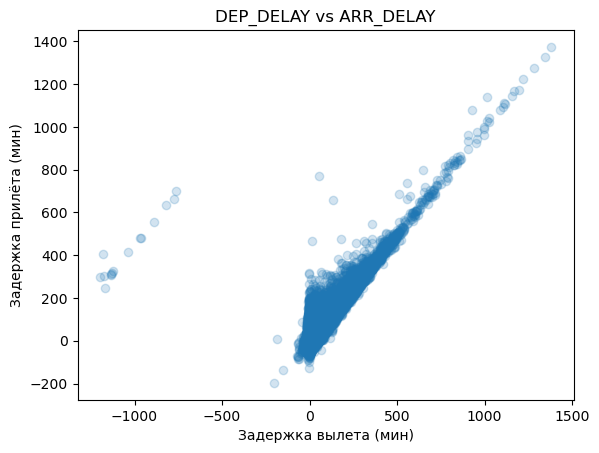

In [137]:
plt.scatter(x, y, alpha=0.2)
plt.title("DEP_DELAY vs ARR_DELAY")
plt.xlabel("Задержка вылета (мин)")
plt.ylabel("Задержка прилёта (мин)")
plt.show()

In [138]:
x = distance_airtime_rdd.map(lambda x: x[0]).collect()
y = distance_airtime_rdd.map(lambda x: x[1]).collect()

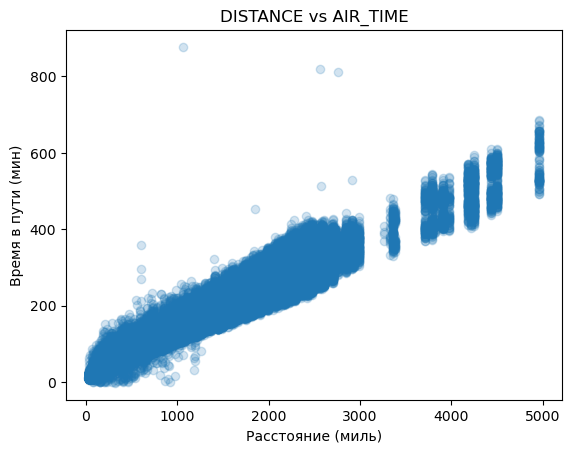

In [139]:
plt.scatter(x, y, alpha=0.2)
plt.title("DISTANCE vs AIR_TIME")
plt.xlabel("Расстояние (миль)")
plt.ylabel("Время в пути (мин)")
plt.show()

In [140]:
x = dep_time_delay_rdd.map(lambda x: x[0]).collect()
y = dep_time_delay_rdd.map(lambda x: x[1]).collect()

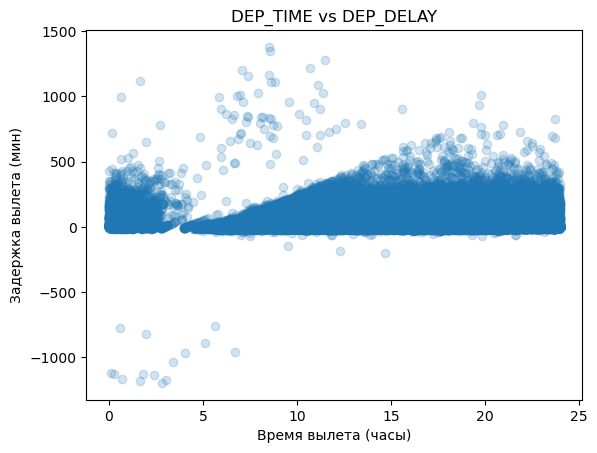

In [141]:
plt.scatter(x, y, alpha=0.2)
plt.title("DEP_TIME vs DEP_DELAY")
plt.xlabel("Время вылета (часы)")
plt.ylabel("Задержка вылета (мин)")
plt.show()

# Задание 4. Классификация рейсов по "пунктуальности"

In [142]:
def classify_flight(dep_delay):
    if dep_delay is None:
        return "unknown"
    if dep_delay < 0:
        return "досрочные"
    elif dep_delay <= 5:
        return "пунктуальные"
    elif dep_delay <= 15:
        return "незначительные задержки"
    else:
        return "существенные задержки"


In [144]:
classified_rdd = rdd.filter(lambda x: x['DEP_DELAY'] is not None) \
                            .map(lambda x: (classify_flight(x['DEP_DELAY']), 1)) \
                            .reduceByKey(lambda a, b: a + b)

In [145]:
distribution = classified_rdd.collect()
distribution

[('существенные задержки', 175683),
 ('досрочные', 468153),
 ('незначительные задержки', 99857),
 ('пунктуальные', 256307)]

In [146]:
categories = [x[0] for x in distribution]
counts = [x[1] for x in distribution]

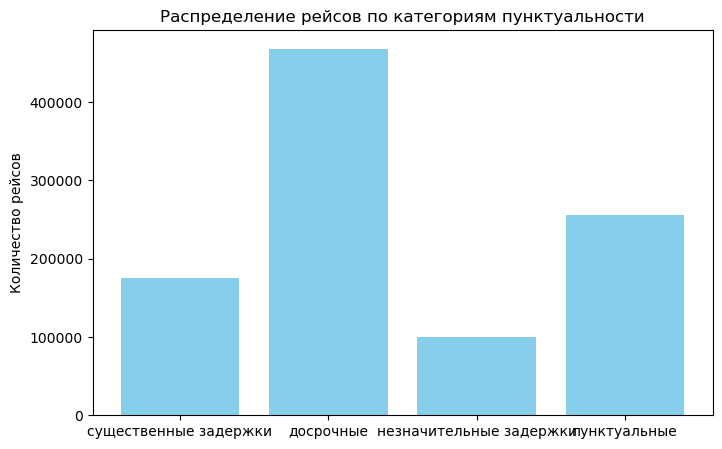

In [147]:
plt.figure(figsize=(8,5))
plt.bar(categories, counts, color='skyblue')
plt.title("Распределение рейсов по категориям пунктуальности")
plt.ylabel("Количество рейсов")
plt.show()

In [149]:
on_time_rdd = rdd.filter(lambda x: classify_flight(x['DEP_DELAY']) == "пунктуальные" and x['ARR_DELAY'] is not None)


In [150]:
stats = on_time_rdd.map(lambda x: (x['DISTANCE'], x['AIR_TIME'], x['ARR_DELAY'])) \
                   .map(lambda x: (x[0], x[1], x[2], 1)) \
                   .reduce(lambda a, b: (a[0]+b[0], a[1]+b[1], a[2]+b[2], a[3]+b[3]))

In [152]:
avg_distance = stats[0] / stats[3]
avg_airtime = stats[1] / stats[3]
avg_arr_delay = stats[2] / stats[3]
print(f"Среднее расстояние пунктуальных рейсов: {avg_distance:.2f} миль")
print(f"Среднее время полета пунктуальных рейсов: {avg_airtime:.2f} мин")
print(f"Средняя задержка прилета пунктуальных рейсов: {avg_arr_delay:.2f} мин")

Среднее расстояние пунктуальных рейсов: 721.73 миль
Среднее время полета пунктуальных рейсов: 103.23 мин
Средняя задержка прилета пунктуальных рейсов: -2.08 мин


# Задание 5. Пространственный анализ

In [153]:
def distance_category(distance):
    if distance is None:
        return "unknown"
    if distance < 500:
        return "короткие"
    elif distance <= 1500:
        return "средние"
    else:
        return "длинные"


In [155]:
distance_rdd = rdd.filter(lambda x: x['DISTANCE'] is not None and x['AIR_TIME'] is not None) \
                          .map(lambda x: (
                              distance_category(x['DISTANCE']),
                              (x['DEP_DELAY'] or 0, x['ARR_DELAY'] or 0, x['AIR_TIME'], x['DISTANCE'], 1)
                          ))

In [156]:
distance_stats = distance_rdd.reduceByKey(lambda a, b: (
    a[0]+b[0],  # DEP_DELAY
    a[1]+b[1],  # ARR_DELAY
    a[2]+b[2],  # AIR_TIME
    a[3]+b[3],  # DISTANCE
    a[4]+b[4]   # count
)).mapValues(lambda x: (
    x[0]/x[4],  # средняя задержка вылета
    x[1]/x[4],  # средняя задержка прилёта
    x[2]/x[4],  # среднее время полета
    x[3]/x[4],  # среднее расстояние
    x[2]/x[3]   # средняя "скорость"
))

In [159]:
distance_results = distance_stats.collect()
distance_results

[('средние',
  (9.38846356574411,
   6.957705069602261,
   120.3736531033708,
   854.7803553992517,
   0.14082407526451232)),
 ('длинные',
  (9.641838483223703,
   6.050807952388849,
   256.23936395629505,
   2027.7611980174304,
   0.12636565104748218)),
 ('короткие',
  (7.603717756651686,
   5.887538561341118,
   51.98451945918448,
   292.7667441393762,
   0.1775629250924635))]

In [160]:
categories = [x[0] for x in distance_results]
dep_delay = [x[1][0] for x in distance_results]
arr_delay = [x[1][1] for x in distance_results]
avg_speed = [x[1][4] for x in distance_results]

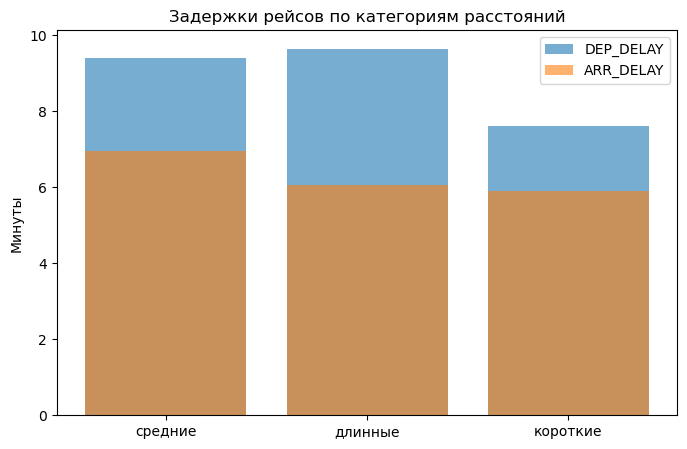

In [161]:
plt.figure(figsize=(8,5))
plt.bar(categories, dep_delay, alpha=0.6, label="DEP_DELAY")
plt.bar(categories, arr_delay, alpha=0.6, label="ARR_DELAY")
plt.title("Задержки рейсов по категориям расстояний")
plt.ylabel("Минуты")
plt.legend()
plt.show()

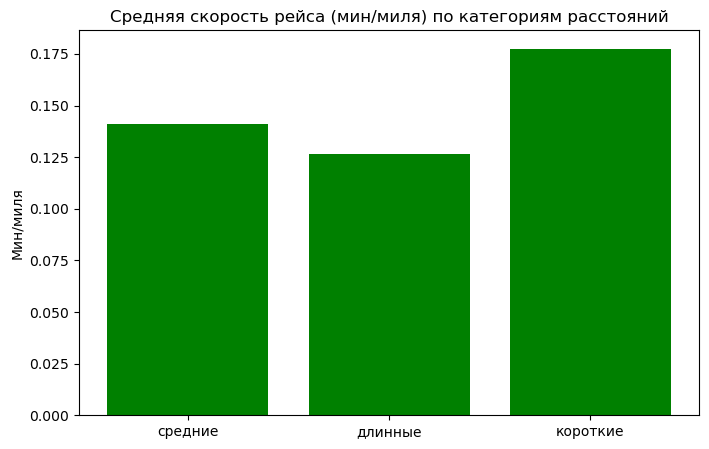

In [162]:
plt.figure(figsize=(8,5))
plt.bar(categories, avg_speed, color='green')
plt.title("Средняя скорость рейса (мин/миля) по категориям расстояний")
plt.ylabel("Мин/миля")
plt.show()

In [163]:
avg_speed_dict = {x[0]: x[1][4] for x in distance_results}

In [165]:
anomalies_rdd = rdd.filter(lambda x: x['DISTANCE'] and x['AIR_TIME']) \
    .filter(lambda x: abs((x['AIR_TIME']/x['DISTANCE']) - avg_speed_dict[distance_category(x['DISTANCE'])]) > 0.5*avg_speed_dict[distance_category(x['DISTANCE'])])

In [166]:
anomalies_rdd.count()

29451

In [168]:
anomalies_rdd.take(3)

[{'FL_DATE': '2006-01-22',
  'DEP_DELAY': -1,
  'ARR_DELAY': 39,
  'AIR_TIME': 66,
  'DISTANCE': 204,
  'DEP_TIME': 15.716666,
  'ARR_TIME': 17.4},
 {'FL_DATE': '2006-01-19',
  'DEP_DELAY': -10,
  'ARR_DELAY': 49,
  'AIR_TIME': 157,
  'DISTANCE': 733,
  'DEP_TIME': 8.833333,
  'ARR_TIME': 11.516666},
 {'FL_DATE': '2006-01-02',
  'DEP_DELAY': 26,
  'ARR_DELAY': 64,
  'AIR_TIME': 156,
  'DISTANCE': 733,
  'DEP_TIME': 10.433333,
  'ARR_TIME': 12.633333}]

In [16]:
spark.stop()